# Final diagnostic 03 — Shape features versus readout

**Runs all 30 original Constant-LR checkpoints.** Fits the *same frozen-encoder diagnostic decoders* as the pilot, with no changes to ViT weights. A **single random encoder per seed** is used as a reference for every trained checkpoint belonging to that seed; never count duplicated random outcomes as 30 independent observations.

- Object-level Shape: oracle-centered 5×5 crop, 48-dimensional mean, 1200-dimensional spatial, position-shuffled 1200-dimensional, and patch-scoring head-like readouts. Four-class object labels are additional supervision.
- Scene-level Shape: original frozen head, retrained logistic classifier on the **exact original eight scalars**, and spatial convolution over the frozen 16×16×48 tokens. All use the same binary scene questions and no oracle object positions.
- 35 epochs per trainable decoder, same as the pilot. No dev-driven tuning. Data hashes and checkpoint SHA-256 are verified before beginning. All outputs isolated under `final_five_seeds/readout_probes/` and resumable per checkpoint.

**Important:** a spatial probe's gain over 48-feature pooling is not a controlled capacity ablation; scene-level results are the more relevant original-task diagnostic. These are development measurements.

In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
import torch
from src.medium_visual_world.diagnostic_followup import (
    load_jsonl, count_free, locate_checkpoint, load_frozen_model,
    run_swaps, extract_object_crops, shape_object_probes,
    scene_shape_head_probe, make_swap
)
from src.medium_visual_world.final_diagnostic_followup import (
    SCHEDULES, SEEDS, STEPS, experiment_grid, experiment_tag,
    validate_manifest, validate_frozen_datasets, verified_sha,
    ensure_run_file, atomic_csv, paired_checkpoint_differences,
    swap_metrics, mean_ci, task_head_competition_controlled
)
from src.medium_visual_world.learning import MediumDataset, AttributeBindingViT, set_seed
OUTPUT = PROJECT_ROOT / "outputs/medium_world/experiments/diagnostic_followup/final_five_seeds"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MANIFEST = validate_manifest(PROJECT_ROOT)   # require the original 30 checkpoints and correct hashes
HASHES = validate_frozen_datasets(PROJECT_ROOT)
print("Validated 30 checkpoints, frozen data hashes, device:", DEVICE)

Validated 30 checkpoints, frozen data hashes, device: cuda


In [ ]:
train_ds = MediumDataset(PROJECT_ROOT / "outputs/medium_world/dataset/train.jsonl")
dev_ds = MediumDataset(PROJECT_ROOT / "outputs/medium_world/dataset/id_dev.jsonl")
folder = OUTPUT/"readout_probes"
folder.mkdir(parents=True,exist_ok=True)
RANDOM_EPOCHS=35
OBJECT_EPOCHS=35
SCENE_EPOCHS=35
print("Training scenes",len(train_ds.images),"ID scenes",len(dev_ds.images))

# One random encoder AND one decoder training per seed, not 30 independent random baselines.
random_records=[]
for seed in SEEDS:
    target=folder/f"random_object_probe_seed{seed}.csv"
    predicted=folder/f"random_object_predictions_seed{seed}.csv"
    cached=ensure_run_file(target,("decoder","accuracy","seed","encoder"),{"seed":seed,"encoder":"random"},n=4)
    if cached is None:
        set_seed(seed)
        random_model=AttributeBindingViT(dim=48,patch_size=4,depth=1).to(DEVICE).eval()
        for p in random_model.parameters():p.requires_grad_(False)
        train_tuple=extract_object_crops(random_model,train_ds,DEVICE)
        dev_tuple=extract_object_crops(random_model,dev_ds,DEVICE)
        metrics,details=shape_object_probes(train_tuple,dev_tuple,seed=seed,alpha=10.0,head_epochs=RANDOM_EPOCHS)
        metrics["encoder"]="random"
        metrics["seed"]=seed
        atomic_csv(metrics,target)
        atomic_csv(details,predicted)
        del train_tuple,dev_tuple,random_model
        print("COMPUTED random baseline seed",seed)
    else:
        metrics=cached
        if not predicted.is_file():raise FileNotFoundError(f"Predictions missing: {predicted}")
        if len(pd.read_csv(predicted))!=sum(len(x["scene"]["objects"]) for x in {r["scene_id"]:r for r in dev_ds.rows}.values()):
            raise ValueError(f"Random probe prediction support mismatch: {predicted}")
        print("VERIFIED random baseline seed",seed)
    random_records.append(metrics)
random_summary = pd.concat(random_records, ignore_index=True)
atomic_csv(random_summary, folder/"random_object_baseline_five_independent_seeds.csv")

trained_records=[]
scene_records=[]
expected_shape_ids=[str(r["id"]) for r in dev_ds.rows if r["template"]=="shape"]
for schedule,seed,step in experiment_grid():
    tag=experiment_tag(schedule,seed,step)
    checkpoint=locate_checkpoint(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    sha=verified_sha(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    object_path=folder/f"object_metrics_{tag}.csv"
    object_preds=folder/f"object_predictions_{tag}.csv"
    scene_path=folder/f"scene_metrics_{tag}.csv"
    scene_preds=folder/f"scene_predictions_{tag}.csv"
    key={"seed":seed,"step":step,"schedule":schedule,"checkpoint_sha256":sha}
    obj=ensure_run_file(object_path,("decoder","accuracy","checkpoint_sha256"),key,n=4)
    scene=ensure_run_file(scene_path,("readout","accuracy","checkpoint_sha256"),key,n=3)
    if obj is None or scene is None:
        model,_=load_frozen_model(checkpoint,DEVICE)
        if obj is None:
            a=extract_object_crops(model,train_ds,DEVICE)
            d=extract_object_crops(model,dev_ds,DEVICE)
            obj,details=shape_object_probes(a,d,seed=seed,alpha=10.0,head_epochs=OBJECT_EPOCHS)
            obj["encoder"]="trained"
            for k,v in key.items():obj[k]=v
            for k,v in key.items():details[k]=v
            atomic_csv(obj,object_path)
            atomic_csv(details,object_preds)
            del a,d,details
        elif not object_preds.is_file():
            raise FileNotFoundError(f"Object probe metrics exist without predictions: {object_preds}")
        if scene is None:
            scene,detail=scene_shape_head_probe(model,train_ds,dev_ds,DEVICE,seed=seed,epochs=SCENE_EPOCHS)
            if len(detail)!=len(expected_shape_ids):raise AssertionError("Scene prediction alignment mismatch")
            detail.insert(0,"example_id",expected_shape_ids)
            for k,v in key.items():scene[k]=v
            detail[k]=v
            atomic_csv(scene,scene_path)
            atomic_csv(detail,scene_preds)
            del detail
        del model
        print("COMPUTED",tag)
    else:
        if not object_preds.is_file() or not scene_preds.is_file():
            raise FileNotFoundError(f"Saved metrics without predictions: {tag}")
        p=pd.read_csv(scene_preds)
        if list(p.example_id.astype(str))!=expected_shape_ids or not p.checkpoint_sha256.eq(sha).all():
            raise AssertionError(f"Stale scene predictions: {tag}")
        print("VERIFIED",tag)
    trained_records.append(obj)
    scene_records.append(scene)
trained_summary=pd.concat(trained_records,ignore_index=True)
scene_summary=pd.concat(scene_records,ignore_index=True)
if len(trained_summary)!=120 or len(scene_summary)!=90:raise AssertionError("Incomplete final study")
atomic_csv(trained_summary,folder/"trained_object_metrics_30_checkpoints.csv")
atomic_csv(scene_summary,folder/"scene_shape_metrics_30_checkpoints.csv")

# Critical: a random seed is a shared reference within that seed across all stages/schedules.
random_comparison=trained_summary.merge(random_summary[["seed","decoder","accuracy"]].rename(columns={"accuracy":"random_accuracy"}),on=["seed","decoder"],validate="many_to_one")
random_comparison["trained_minus_random"]=random_comparison.accuracy-random_comparison.random_accuracy
atomic_csv(random_comparison,folder/"trained_vs_random_paired_by_seed.csv")

contrasts=[]
for name,g in scene_summary.groupby("readout"):
    c=paired_checkpoint_differences(g,["accuracy","balanced_accuracy","tpr","tnr"])
    c["readout"]=name
    contrasts.append(c)
scene_contrasts=pd.concat(contrasts,ignore_index=True)
atomic_csv(scene_contrasts,folder/"scene_shape_five_seed_stage_contrasts.csv")
for step in STEPS:
    sub=scene_summary[scene_summary.step==step].pivot(index=["schedule","seed"],columns="readout",values="accuracy")
    print("Step",step,"spatial minus original, by schedule:")
    for sched,g in sub.groupby(level=0):
        print(sched,mean_ci((g.spatial_conv_probe-g.original_frozen_model).to_numpy()))
display(scene_summary.groupby(["schedule","step","readout"]).accuracy.agg(["mean","std"]).round(3))
display(random_comparison.groupby(["decoder","schedule","step"]).trained_minus_random.mean().round(4))

Training scenes 5000 ID scenes 512
COMPUTED random baseline seed 42
COMPUTED random baseline seed 43
COMPUTED random baseline seed 44
COMPUTED random baseline seed 45
COMPUTED random baseline seed 46
COMPUTED mixed_seed42_step5400
COMPUTED mixed_seed42_step7200
COMPUTED mixed_seed42_step9000
COMPUTED mixed_seed43_step5400
COMPUTED mixed_seed43_step7200
COMPUTED mixed_seed43_step9000
COMPUTED mixed_seed44_step5400
COMPUTED mixed_seed44_step7200
COMPUTED mixed_seed44_step9000
COMPUTED mixed_seed45_step5400
COMPUTED mixed_seed45_step7200
COMPUTED mixed_seed45_step9000
COMPUTED mixed_seed46_step5400
COMPUTED mixed_seed46_step7200
COMPUTED mixed_seed46_step9000
COMPUTED prereq_mixed_pair_focus_seed42_step5400
COMPUTED prereq_mixed_pair_focus_seed42_step7200
COMPUTED prereq_mixed_pair_focus_seed42_step9000
COMPUTED prereq_mixed_pair_focus_seed43_step5400
COMPUTED prereq_mixed_pair_focus_seed43_step7200
COMPUTED prereq_mixed_pair_focus_seed43_step9000
COMPUTED prereq_mixed_pair_focus_seed44_s

mean    std
schedule                step readout                            
mixed                   5400 original_frozen_model  0.638  0.025
                             retrained_head_on_8    0.641  0.017
                             spatial_conv_probe     0.693  0.031
                        7200 original_frozen_model  0.651  0.016
                             retrained_head_on_8    0.662  0.013
                             spatial_conv_probe     0.688  0.037
                        9000 original_frozen_model  0.678  0.013
                             retrained_head_on_8    0.670  0.004
                             spatial_conv_probe     0.685  0.039
prereq_mixed_pair_focus 5400 original_frozen_model  0.644  0.029
                             retrained_head_on_8    0.651  0.024
                             spatial_conv_probe     0.668  0.043
                        7200 original_frozen_model  0.571  0.038
                             retrained_head_on_8    0.612  0.016
                             spatial_conv_probe     0.661  0.026
                        9000 original_frozen_model  0.669  0.018
                             retrained_head_on_8    0.677  0.012
                             spatial_conv_probe     0.682  0.022

decoder           schedule                 step
head_like_object  mixed                    5400    0.0373
                                           7200    0.0268
                                           9000    0.0386
                  prereq_mixed_pair_focus  5400    0.0358
                                           7200    0.0527
                                           9000    0.0513
mean48            mixed                    5400    0.0072
                                           7200    0.0117
                                           9000    0.0082
                  prereq_mixed_pair_focus  5400    0.0087
                                           7200    0.0145
                                           9000    0.0182
shuffled1200      mixed                    5400   -0.0016
                                           7200   -0.0029
                                           9000   -0.0048
                  prereq_mixed_pair_focus  5400    0.0022
                        

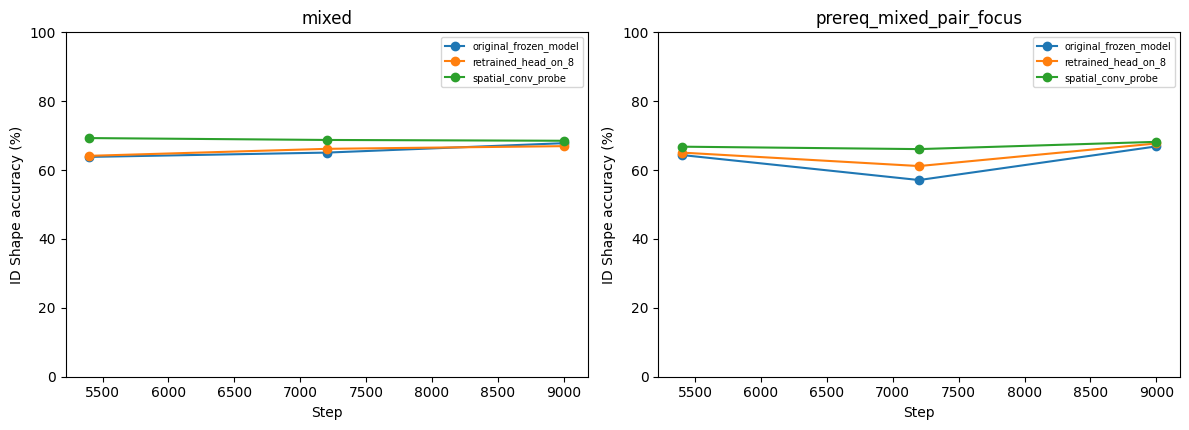

In [ ]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for j,schedule in enumerate(SCHEDULES):
    data=scene_summary[scene_summary.schedule==schedule]
    for label,part in data.groupby("readout"):
        m=part.groupby("step").accuracy.mean()
        axes[j].plot(m.index,100*m.values,marker="o",label=label)
    axes[j].set(title=schedule,ylim=(0,100),xlabel="Step",ylabel="ID Shape accuracy (%)")
    axes[j].legend(fontsize=7)
fig.tight_layout()
fig.savefig(folder/"scene_shape_readout_curves.png",dpi=180)
plt.show()

## Scientific controls and inference

The object-level trained-vs-random comparison is **paired by seed** and the same decoder type; the random baseline is not regenerated when switching curriculum or stage. The original 48-dimensional random patch embedding may be full rank. Strong oracle-centered performance does not establish that the model's own head learns to recognize Shape. Scene-level comparisons share queries and examples; report per-seed improvements and error turnovers instead of pooling all questions as independent replicates. Do not call a gain from a larger convolutional readout a causal proof of spatial geometry's role.